# CEE 902 · Logistic Regression: Predicting Flooding from Precipitation

**Author:** Samuel Asiedu

**Topic:** Binary classification with logistic regression, implemented from scratch with gradient descent.

This notebook models the probability of a *flooding event* given daily precipitation.

## Learning objectives

1. Explain how logistic regression maps inputs to **probabilities** through the sigmoid function.
2. Train and visualize a logistic regression model for **precipitation → flood** classification.
3. Interpret the **decision boundary** (the rainfall threshold at $P = 0.5$).
4. Evaluate model performance with accuracy and a confusion matrix.

## 1. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

RANDOM_SEED = 42

## 2. Background: the sigmoid function

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

The sigmoid maps any real number to the interval $(0, 1)$, which allows the output to be read as a probability. It equals 0.5 at $z = 0$.

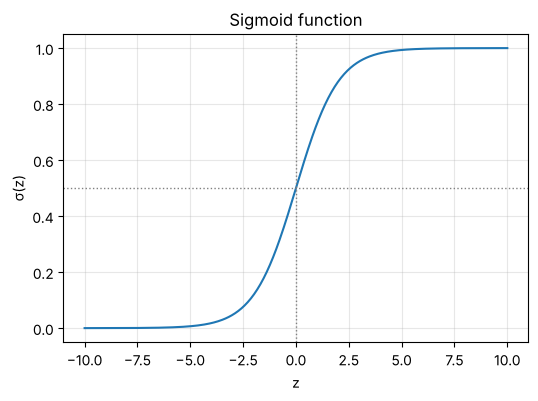

In [2]:
def sigmoid(z):
    # Logistic function, applied element-wise.
    return 1 / (1 + np.exp(-z))


z = np.linspace(-10, 10, 400)
plt.figure(figsize=(6, 4))
plt.plot(z, sigmoid(z))
plt.axhline(0.5, color="gray", linestyle=":", linewidth=1)
plt.axvline(0, color="gray", linestyle=":", linewidth=1)
plt.xlabel("z")
plt.ylabel("σ(z)")
plt.title("Sigmoid function")
plt.grid(True, alpha=0.3)
plt.show()

## 3. Synthetic hydrology dataset

One hundred days are generated with precipitation evenly spaced from 0 to 150 mm. The true flood probability follows a sigmoid centered at **75 mm** with a scale of 10 mm, and each day's outcome is drawn at random from that probability. The data are synthetic and serve only to illustrate the method.

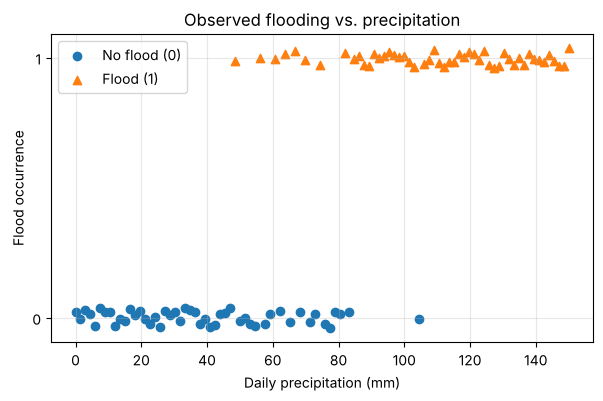

Flood days: 51 of 100


In [3]:
def plot_flood_observations(ax, precip, flood, rng):
    # Scatter the 0/1 outcomes with a small vertical jitter so that points do not overlap.
    jitter = (rng.random(len(precip)) - 0.5) * 0.08
    for label, marker, name in [(0, "o", "No flood (0)"), (1, "^", "Flood (1)")]:
        mask = flood == label
        ax.scatter(precip[mask], flood[mask] + jitter[mask], marker=marker, label=name)
    ax.set_yticks([0, 1])
    ax.set_xlabel("Daily precipitation (mm)")
    ax.grid(True, alpha=0.3)


np.random.seed(RANDOM_SEED)
N = 100
precip = np.linspace(0, 150, N)                        # mm per day
true_prob = sigmoid((precip - 75) / 10)                # latent truth
y = (np.random.rand(N) < true_prob).astype(int)        # 1 = flood, 0 = no flood

plot_rng = np.random.default_rng(RANDOM_SEED)          # used only for plot jitter
fig, ax = plt.subplots(figsize=(7, 4))
plot_flood_observations(ax, precip, y, plot_rng)
ax.set_ylabel("Flood occurrence")
ax.set_title("Observed flooding vs. precipitation")
ax.legend()
plt.show()

print(f"Flood days: {y.sum()} of {N}")

## 4. Model, cost function, and gradient

Precipitation is min-max normalized to $[0, 1]$ for stable gradient updates, and a column of ones is added for the intercept.

**Model:** $h_\theta(x) = \sigma(\theta_0 + \theta_1 x)$

**Cost (binary cross-entropy):**

$$J(\theta) = -\frac{1}{m}\sum_{i=1}^{m}\Big[y^{(i)}\log h_\theta(x^{(i)}) + \big(1 - y^{(i)}\big)\log\big(1 - h_\theta(x^{(i)})\big)\Big]$$

**Gradient:**

$$\nabla J(\theta) = \frac{1}{m}X^{\top}\big(h_\theta(X) - y\big)$$

In [4]:
precip_min, precip_max = precip.min(), precip.max()


def build_design_matrix(precip_mm):
    # Normalize precipitation with the training min/max and prepend the intercept column.
    precip_mm = np.atleast_1d(np.asarray(precip_mm, dtype=float))
    precip_norm = (precip_mm - precip_min) / (precip_max - precip_min)
    return np.column_stack([np.ones(len(precip_norm)), precip_norm])


def get_cost(theta, X, y):
    # Mean binary cross-entropy.
    h = sigmoid(X @ theta)
    h = np.clip(h, 1e-15, 1 - 1e-15)      # numerical safeguard against log(0)
    return -np.mean(y * np.log(h) + (1 - y) * np.log(1 - h))


def gradient_descent(X, y, learning_rate=0.5, iterations=50_000):
    # Batch gradient descent for logistic regression, starting from zero coefficients.
    m = X.shape[0]
    theta = np.zeros(X.shape[1])
    cost_history = np.empty(iterations)

    for i in range(iterations):
        h = sigmoid(X @ theta)                  # predicted probabilities
        cost_history[i] = get_cost(theta, X, y)
        gradient = X.T @ (h - y) / m
        theta = theta - learning_rate * gradient

    return theta, cost_history


X_aug = build_design_matrix(precip)

# Sanity check: with zero coefficients every probability is 0.5, so J must equal log(2).
print(f"Cost at theta = 0: {get_cost(np.zeros(2), X_aug, y):.6f} (expected {np.log(2):.6f})")

Cost at theta = 0: 0.693147 (expected 0.693147)


## 5. Train the model

theta (intercept, slope): [-6.5585 13.3881]
Final cost: 0.2418
Training accuracy: 88.0%


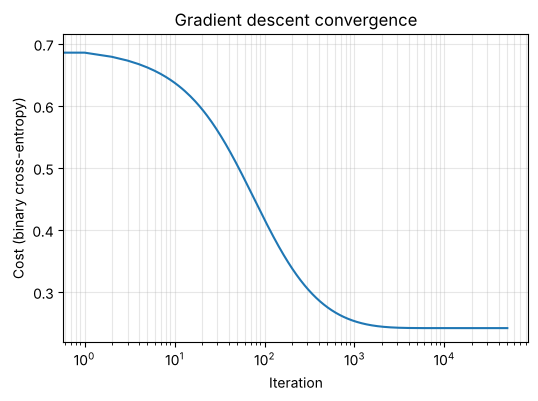

In [5]:
LEARNING_RATE = 0.5
ITERATIONS = 50_000

theta, J_hist = gradient_descent(X_aug, y, LEARNING_RATE, ITERATIONS)

probs = sigmoid(X_aug @ theta)            # P(flood = 1) for every day
y_pred = (probs >= 0.5).astype(int)       # classify as flood when P >= 0.5
acc = np.mean(y_pred == y)

print("theta (intercept, slope):", np.round(theta, 4))
print(f"Final cost: {J_hist[-1]:.4f}")
print(f"Training accuracy: {acc:.1%}")

plt.figure(figsize=(6, 4))
plt.plot(J_hist)
plt.xscale("log")
plt.xlabel("Iteration")
plt.ylabel("Cost (binary cross-entropy)")
plt.title("Gradient descent convergence")
plt.grid(True, alpha=0.3, which="both")
plt.show()

## 6. Decision boundary

The model predicts a flood when $P \geq 0.5$, which occurs when $\theta_0 + \theta_1 x_{\text{norm}} \geq 0$. The boundary is therefore at $x_{\text{norm}} = -\theta_0/\theta_1$, which is converted back to millimeters below.

Decision boundary: 73.5 mm/day (true midpoint of the simulation: 75 mm/day)


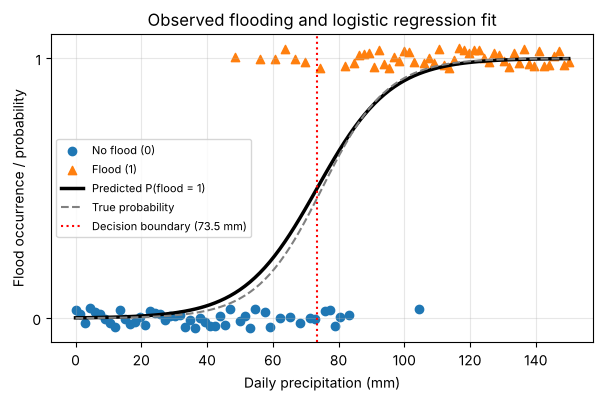

In [6]:
boundary_norm = -theta[0] / theta[1]
boundary_mm = precip_min + boundary_norm * (precip_max - precip_min)
print(f"Decision boundary: {boundary_mm:.1f} mm/day (true midpoint of the simulation: 75 mm/day)")

fig, ax = plt.subplots(figsize=(7, 4))
plot_flood_observations(ax, precip, y, plot_rng)
ax.plot(precip, probs, color="black", linewidth=2.5, label="Predicted P(flood = 1)")
ax.plot(precip, true_prob, color="gray", linestyle="--", linewidth=1.5, label="True probability")
ax.axvline(boundary_mm, color="red", linestyle=":", label=f"Decision boundary ({boundary_mm:.1f} mm)")
ax.set_ylabel("Flood occurrence / probability")
ax.set_title("Observed flooding and logistic regression fit")
ax.legend(loc="center left", fontsize=8)
plt.show()

## 7. Evaluation

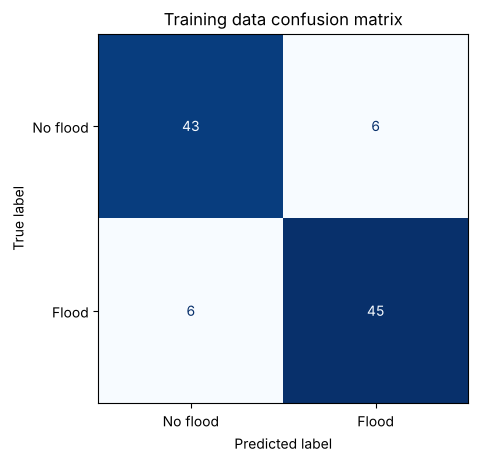

Correct: 88 of 100; missed floods: 6; false alarms: 6


In [7]:
cm = confusion_matrix(y, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["No flood", "Flood"]).plot(cmap="Blues", colorbar=False)
plt.title("Training data confusion matrix")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Correct: {tn + tp} of {N}; missed floods: {fn}; false alarms: {fp}")

## 8. Interpretation

- **Fitted model.** The estimated decision boundary is about 73.5 mm/day, close to the 75 mm/day midpoint used to simulate the data. The fitted curve follows the true probability curve closely.
- **Accuracy.** Training accuracy is 88%. Perfect accuracy is not attainable here because the outcomes are random: near the boundary a flood occurs on some days and not on others at nearly the same precipitation, and no threshold can separate them.
- **Limitation.** Accuracy is computed on the same 100 observations used for fitting, so it measures training fit. Performance on new data requires a separate held-out set.

### Predict the flood probability for a new day

In [8]:
def predict_flood_probability(precip_mm):
    # Probability of flooding for one or more daily precipitation values in mm.
    return sigmoid(build_design_matrix(precip_mm) @ theta)


for rain_mm in [40, 75, 110]:
    probability = predict_flood_probability(rain_mm)[0]
    print(f"{rain_mm:>4} mm/day -> P(flood) = {probability:.3f}")

  40 mm/day -> P(flood) = 0.048
  75 mm/day -> P(flood) = 0.534
 110 mm/day -> P(flood) = 0.963
